<a href="https://colab.research.google.com/github/Blessy373/Data-Analytics/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [76]:
import pandas as pd

In [77]:
df=pd.read_csv('/content/Student_Placement_Career_Prediction_Dataset.csv')

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  10000 non-null  int64  
 1   age                         10000 non-null  int64  
 2   gender                      10000 non-null  object 
 3   branch                      10000 non-null  object 
 4   cgpa                        10000 non-null  float64
 5   internship_count            10000 non-null  int64  
 6   project_count               10000 non-null  int64  
 7   certifications_count        10000 non-null  int64  
 8   coding_skills_score         10000 non-null  int64  
 9   communication_skills_score  10000 non-null  int64  
 10  soft_skills_score           10000 non-null  int64  
 11  hackathon_participation     10000 non-null  object 
 12  placement_status            10000 non-null  object 
dtypes: float64(1), int64(8), object(

In [79]:
df['placement_status'].unique()

array(['Placed', 'Not Placed'], dtype=object)

#preprocessing

--- CORRELATION WITH TARGET (Numerical Features) ---
placement_encoded             1.000000
cgpa                          0.486511
internship_count              0.381788
certifications_count          0.336285
project_count                 0.299132
coding_skills_score           0.155319
communication_skills_score    0.109797
soft_skills_score             0.089600
age                          -0.000877
Name: placement_encoded, dtype: float64


/tmp/ipykernel_1776/4197586019.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='placement_status', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_1776/4197586019.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='placement_status', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_1776/4197586019.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='placement_status', y=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_1776/4197586019.py:25: FutureWarning: 

Passing `palette` without assigning `hue` 

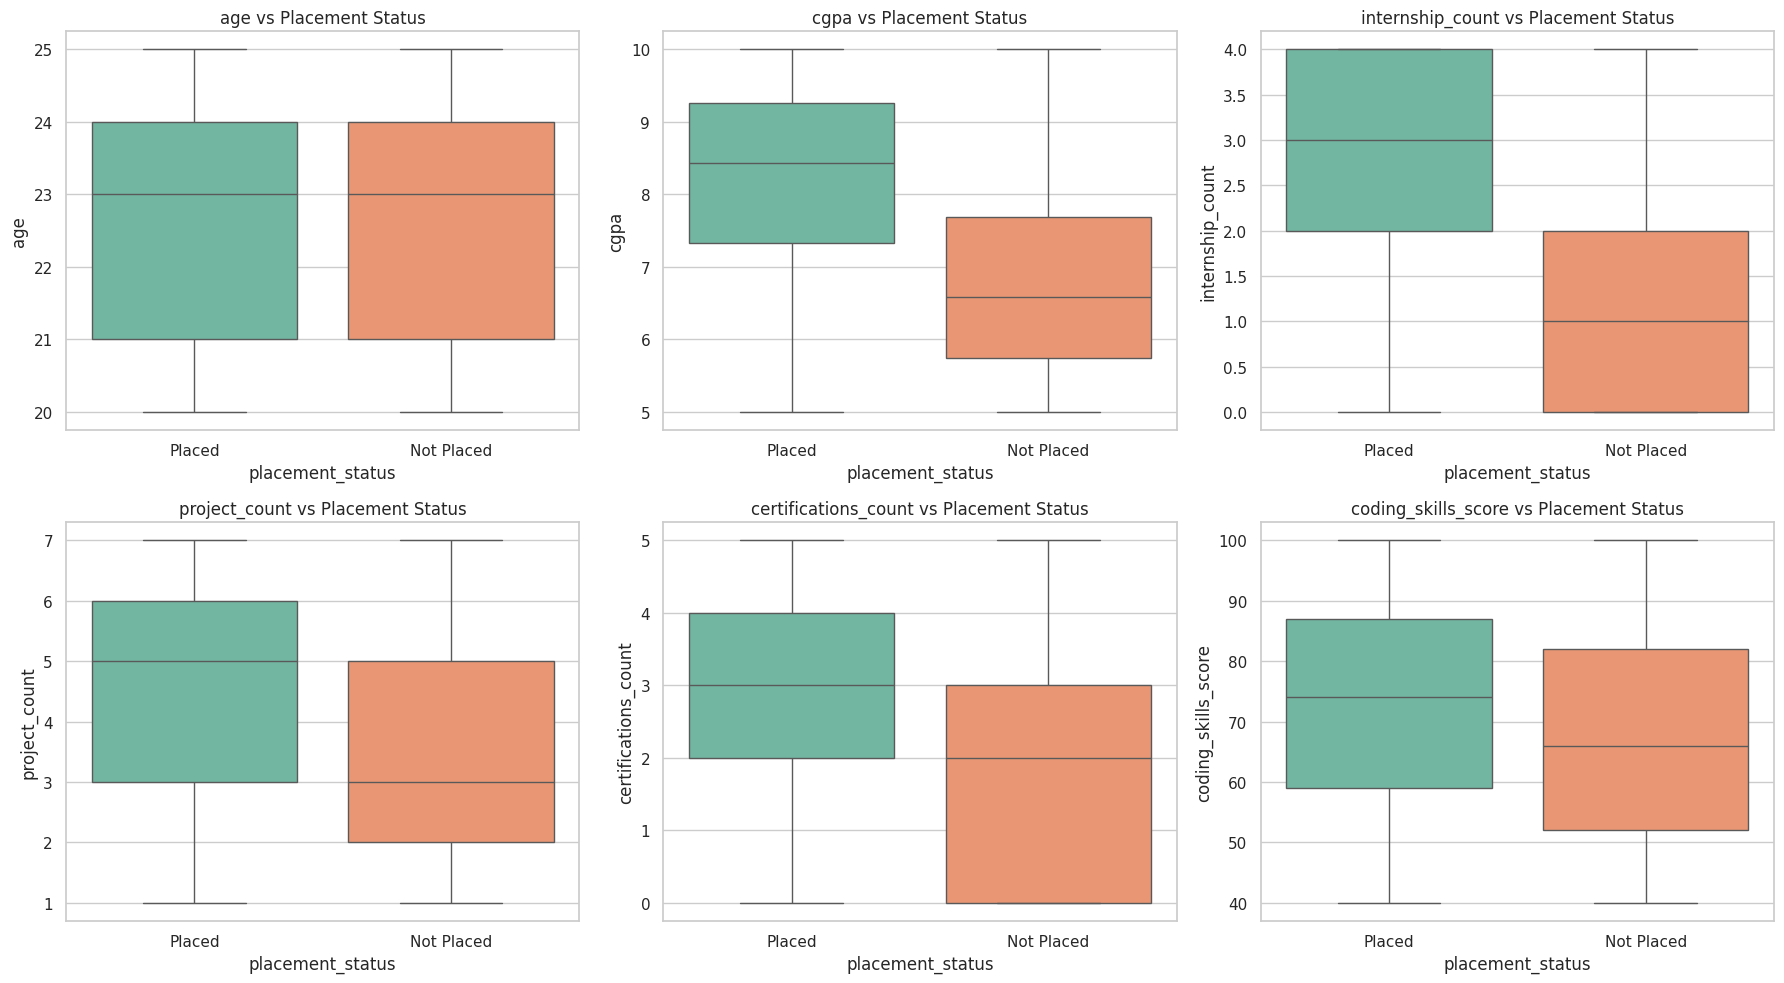


--- CATEGORICAL RELATIONSHIPS (Proportions) ---

Percentage placement by gender:
placement_status  Not Placed     Placed
gender                                 
Female             48.684211  51.315789
Male               49.839486  50.160514


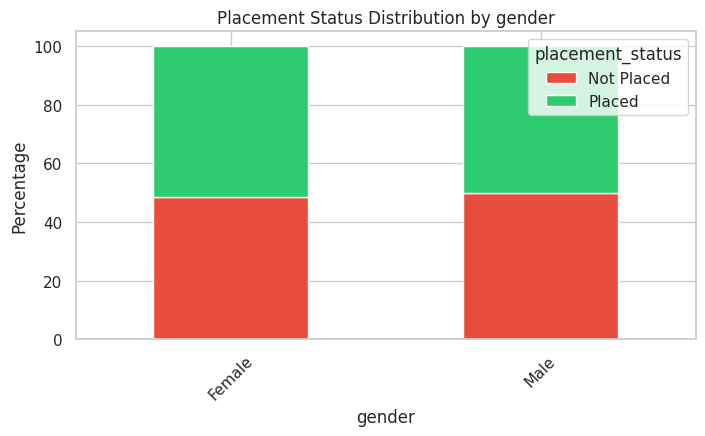


Percentage placement by branch:
placement_status  Not Placed     Placed
branch                                 
CSE                48.678802  51.321198
Civil              49.970078  50.029922
ECE                50.154416  49.845584
EEE                49.396135  50.603865
IT                 48.430233  51.569767
Mechanical         48.988351  51.011649


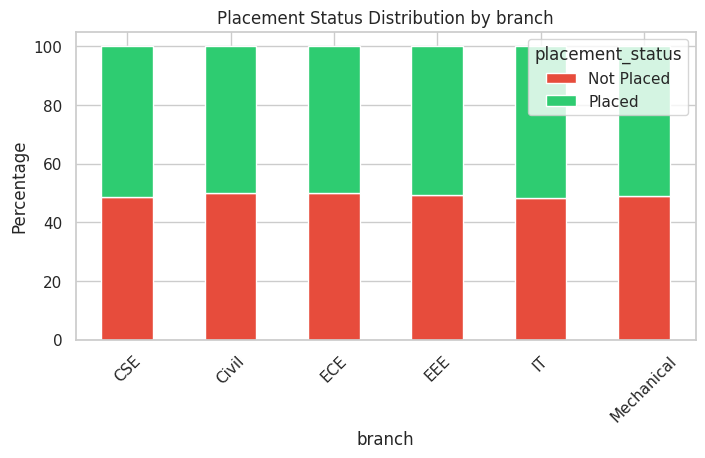


Percentage placement by hackathon_participation:
placement_status         Not Placed     Placed
hackathon_participation                       
No                        57.686854  42.313146
Yes                       41.042860  58.957140


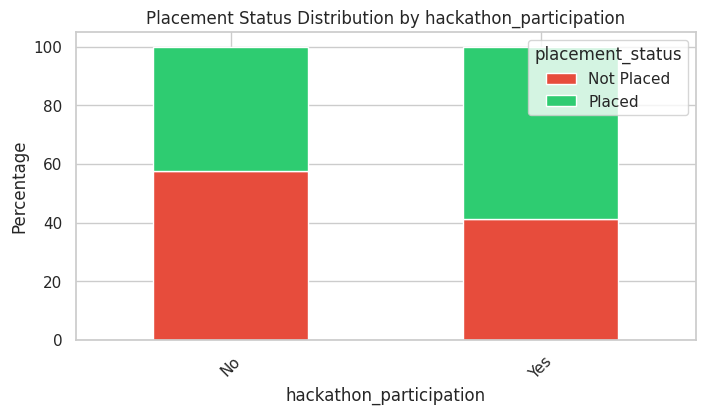

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Map target column to numeric to calculate correlations easily
df['placement_encoded'] = df['placement_status'].map({'Placed': 1, 'Not Placed': 0})

# Identify numerical and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns.drop(['student_id', 'placement_encoded'])
cat_cols = df.select_dtypes(include=['object']).columns.drop(['placement_status'])

print("--- CORRELATION WITH TARGET (Numerical Features) ---")
correlations = df[list(num_cols) + ['placement_encoded']].corr()['placement_encoded'].sort_values(ascending=False)
print(correlations)

# Plotting distribution of top numerical features by placement status
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols[:6]): # visualising the first 6 numerical features
    sns.boxplot(data=df, x='placement_status', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs Placement Status')

plt.tight_layout()
plt.show()

# 2. Analyzing Categorical Features with Cross-tabulation
print("\n--- CATEGORICAL RELATIONSHIPS (Proportions) ---")
for col in cat_cols:
    crosstab = pd.crosstab(df[col], df['placement_status'], normalize='index') * 100
    print(f"\nPercentage placement by {col}:")
    print(crosstab)

    # Plot stacked bar chart for each categorical column
    crosstab.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], figsize=(8, 4))
    plt.title(f'Placement Status Distribution by {col}')
    plt.ylabel('Percentage')
    plt.xticks(rotation=45)
    plt.show()

In [98]:
# Drop student_id (unique identifier), age (no correlation), and gender (near-identical distributions)
columns_to_drop = ['student_id', 'age', 'gender','placement_status']
df_cleaned = df.drop(columns=columns_to_drop, errors='ignore')

# Display the columns left in our cleaned dataset
print("Columns retained for modeling:")
print(list(df_cleaned.columns))

# Display the first few rows of the cleaned DataFrame
display(df_cleaned.head())

Columns retained for modeling:
['branch', 'cgpa', 'internship_count', 'project_count', 'certifications_count', 'coding_skills_score', 'communication_skills_score', 'soft_skills_score', 'hackathon_participation', 'placement_encoded']


,branch,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score,hackathon_participation,placement_encoded
0,IT,8.99,4,6,2,41,71,59,Yes,1
1,Mechanical,8.36,4,7,5,42,64,97,No,1
2,EEE,7.18,4,5,2,84,98,51,No,1
3,Mechanical,6.28,0,2,4,60,100,92,No,0
4,IT,5.30,3,4,1,78,61,77,No,0


In [82]:
df['branch'].unique()

array(['IT', 'Mechanical', 'EEE', 'CSE', 'ECE', 'Civil'], dtype=object)

In [83]:
x=df.drop(['placement_encoded','placement_status'],axis=1)
y=df['placement_encoded']

In [84]:
x_en=pd.get_dummies(x,columns=cat_cols,drop_first=True)

In [85]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x_en,y,test_size=0.2,random_state=42)

In [86]:
x_train.head(3)

,student_id,age,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score,gender_Male,branch_Civil,branch_ECE,branch_EEE,branch_IT,branch_Mechanical,hackathon_participation_Yes
9254,9255,21,6.55,4,6,1,57,59,60,False,False,False,True,False,False,False
1561,1562,21,5.90,2,1,1,68,50,75,True,False,False,False,False,False,False
1670,1671,22,5.95,3,4,5,78,83,64,False,False,False,False,False,True,False


In [87]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [94]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [95]:
knn.score(x_test,y_test)

0.8065

In [96]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
y_pred=knn.predict(x_test)
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.8065
              precision    recall  f1-score   support

           0       0.79      0.80      0.80       951
           1       0.82      0.81      0.81      1049

    accuracy                           0.81      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.81      0.81      0.81      2000



In [91]:
cm=confusion_matrix(y_test,y_pred)
cm

array([[845, 106],
       [ 86, 963]])

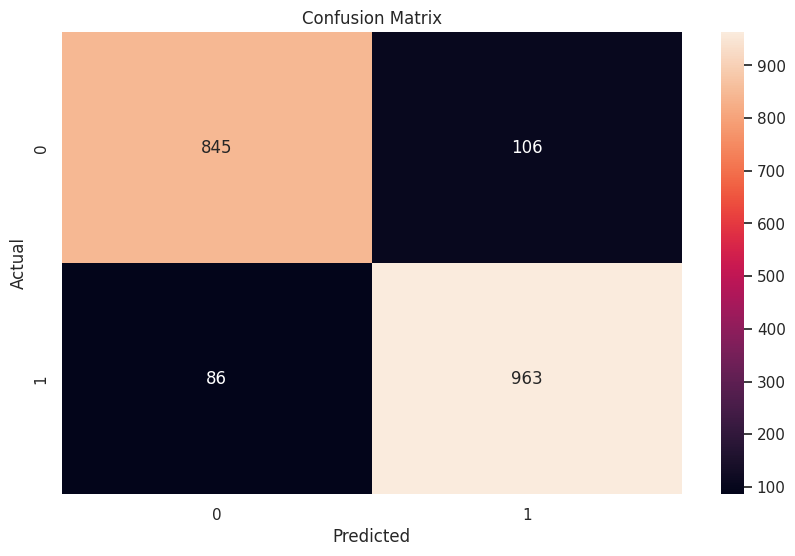

In [92]:
plt.figure(figsize=(10,6))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#Chosing best Kvalue:

14
Best k value: 15
Maximum Accuracy: 0.9040


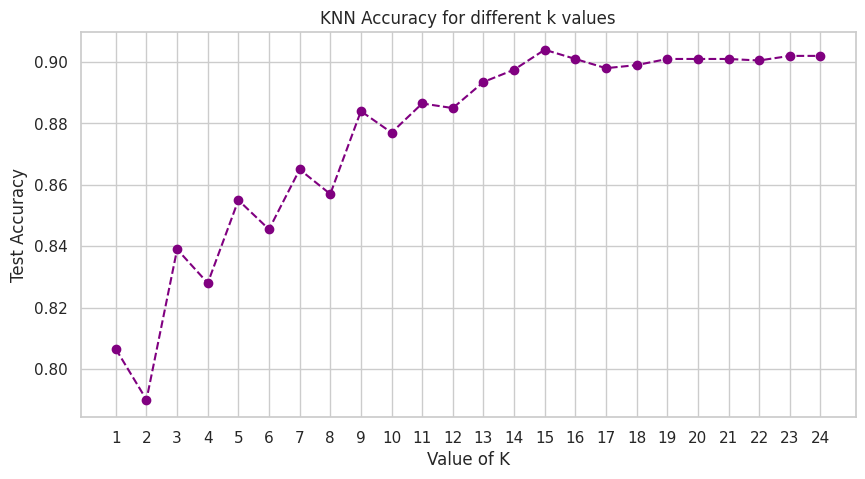

In [104]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Define the range of k values to explore (from 1 to 20)
ks = range(1, 25)
scores = []

# Loop through each k value
for k in ks:
    # 1. Initialize KNN Classifier with the current k
    model = KNeighborsClassifier(n_neighbors=k)

    # 2. Train the model
    model.fit(x_train, y_train)

    # 3. Predict the test dataset
    pred = model.predict(x_test)

    # 4. Measure accuracy and save it (Fixing the previous loop bug)
    scores.append(accuracy_score(y_test, pred))

# Find the index of the maximum accuracy score and get its corresponding k
a=np.argmax(scores)
print(a)
best_k = ks[int(np.argmax(scores))]
print(f"Best k value: {best_k}")
print(f"Maximum Accuracy: {max(scores):.4f}")

# Visualize the relationship between k and accuracy
plt.figure(figsize=(10, 5))
plt.plot(ks, scores, marker='o', color='purple', linestyle='--')
plt.title('KNN Accuracy for different k values')
plt.xlabel('Value of K')
plt.ylabel('Test Accuracy')
plt.xticks(ks)
plt.show()